In [3]:
from pathlib import Path
import json
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)


PyTorch: 2.5.1
Device: cuda


In [ ]:
DATA_DIR = Path(r'D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DATA')
DATA_FILE = DATA_DIR / 'lucknow_unified_lstm_dataset_aug2024_dec2025.csv'
# SUMMARY_FILE = DATA_DIR / 'lucknow_unified_lstm_dataset_summary.csv'
RESULTS_DIR = Path(r'D:\\IMD\\Lucknow\\result\\train_lucknow_lstm')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR = RESULTS_DIR
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMNS = ['CLOUD_Vertical_Visibility', 'VIS_Visibility_MOR']
TIMESTAMP_COLUMN = 'Datetime'
LOOKBACK = 96
HORIZON = 1
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
BATCH_SIZE = 256
EPOCHS = 50
PATIENCE = 8

assert DATA_FILE.exists(), f'Missing data file: {DATA_FILE}'
# assert SUMMARY_FILE.exists(), f'Missing summary file: {SUMMARY_FILE}'


In [ ]:
# NOTE: The summary file is not used in this script, but it has been ran before you could see the output.
# summary = pd.read_csv(SUMMARY_FILE)
# display(summary)

df = pd.read_csv(DATA_FILE, low_memory=False)
df[TIMESTAMP_COLUMN] = pd.to_datetime(df[TIMESTAMP_COLUMN], errors='coerce')
df = (
    df.dropna(subset=[TIMESTAMP_COLUMN] + TARGET_COLUMNS)
      .drop_duplicates(subset=[TIMESTAMP_COLUMN])
      .sort_values(TIMESTAMP_COLUMN)
      .reset_index(drop=True)
)

missing_targets = [column for column in TARGET_COLUMNS if column not in df.columns]
assert not missing_targets, f'Missing target columns: {missing_targets}'
assert df[TIMESTAMP_COLUMN].is_monotonic_increasing
assert not df[TIMESTAMP_COLUMN].duplicated().any()
print('Rows:', len(df))
print('Date range:', df[TIMESTAMP_COLUMN].min(), 'to', df[TIMESTAMP_COLUMN].max())
print('Target missing values:', df[TARGET_COLUMNS].isna().sum().to_dict())


,Input_Directory,Output_File,Start_Date_Inclusive,End_Date_Exclusive,Files_Discovered,Files_Processed,Files_Failed,Rows_Read,Rows_In_Date_Range,Invalid_Datetime_Rows,Duplicate_Timestamp_Rows_Removed,Rows_Written,Columns_Written,Column_Names
0,D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DATA,D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DA...,2024-08-01,2026-01-01,541,541,0,2765299,2520761,0,0,2520761,23,"Datetime, CLOUD_Cloud_Base_1, CLOUD_Cloud_Base..."


Rows: 2520761
Date range: 2024-08-08 00:00:00 to 2025-12-31 23:59:45
Target missing values: {'CLOUD_Vertical_Visibility': 0, 'VIS_Visibility_MOR': 0}


In [6]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
feature_columns = numeric_columns.copy()
assert all(column in feature_columns for column in TARGET_COLUMNS)

n_rows = len(df)
train_end = int(n_rows * TRAIN_RATIO)
validation_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))

train_frame = df.iloc[:train_end].copy()
validation_frame = df.iloc[train_end:validation_end].copy()
test_frame = df.iloc[validation_end:].copy()

# Clean invalid numeric values before calculating training statistics.
for frame in (train_frame, validation_frame, test_frame):
    frame[feature_columns] = frame[feature_columns].replace([np.inf, -np.inf], np.nan)

# Drop features that contain no usable training observations.
usable_feature_columns = [
    column for column in feature_columns
    if train_frame[column].notna().any()
]
dropped_feature_columns = [
    column for column in feature_columns
    if column not in usable_feature_columns
]
feature_columns = usable_feature_columns
assert all(column in feature_columns for column in TARGET_COLUMNS)

# Imputation statistics are learned from the training period only.
train_medians = train_frame[feature_columns].median()
train_medians = train_medians.fillna(0.0)
for frame in (train_frame, validation_frame, test_frame):
    frame[feature_columns] = frame[feature_columns].fillna(train_medians)

feature_scaler = StandardScaler()
target_scaler = StandardScaler()
feature_scaler.fit(train_frame[feature_columns])
target_scaler.fit(train_frame[TARGET_COLUMNS])

def transform_frame(frame):
    features = feature_scaler.transform(frame[feature_columns]).astype(np.float32)
    targets = target_scaler.transform(frame[TARGET_COLUMNS]).astype(np.float32)
    if not np.isfinite(features).all() or not np.isfinite(targets).all():
        raise ValueError('Non-finite values remain after imputation and scaling.')
    return features, targets

train_features, train_targets = transform_frame(train_frame)
validation_features, validation_targets = transform_frame(validation_frame)
test_features, test_targets = transform_frame(test_frame)
print('Features:', len(feature_columns), feature_columns)
print('Dropped all-null training features:', dropped_feature_columns)
print('Split sizes:', train_features.shape, validation_features.shape, test_features.shape)


Features: 21 ['CLOUD_Cloud_Base_1', 'CLOUD_Cloud_Base_2', 'CLOUD_Cloud_Base_3', 'CLOUD_OCTA1', 'CLOUD_OCTA2', 'CLOUD_OCTA3', 'CLOUD_OCTA4', 'CLOUD_Vertical_Visibility', 'PTU_Pressure_QNH', 'PTU_Temperature', 'PTU_DewPoint', 'PTU_Humidity', 'PW_Rain_Intensity', 'PW_Rain_Sum', 'VIS_Visibility_MOR', 'VIS_RVR', 'WIND_Wind_Dir', 'WIND_Wind_Speed', 'WIND_Wind_Gust', 'Hour_Sin', 'Hour_Cos']
Dropped all-null training features: ['CLOUD_SITE']
Split sizes: (1764532, 21) (378114, 21) (378115, 21)


In [7]:
def make_sequences(features, targets, lookback, horizon):
    last_start = len(features) - lookback - horizon + 1
    if last_start <= 0:
        raise ValueError('Split is shorter than LOOKBACK + HORIZON.')
    x = np.empty((last_start, lookback, features.shape[1]), dtype=np.float32)
    y = np.empty((last_start, targets.shape[1]), dtype=np.float32)
    for index in range(last_start):
        x[index] = features[index:index + lookback]
        y[index] = targets[index + lookback + horizon - 1]
    return x, y

X_train, y_train = make_sequences(train_features, train_targets, LOOKBACK, HORIZON)
X_validation, y_validation = make_sequences(validation_features, validation_targets, LOOKBACK, HORIZON)
X_test, y_test = make_sequences(test_features, test_targets, LOOKBACK, HORIZON)
print('Sequence shapes:', X_train.shape, y_train.shape, X_validation.shape, y_validation.shape, X_test.shape, y_test.shape)


Sequence shapes: (1764436, 96, 21) (1764436, 2) (378018, 96, 21) (378018, 2) (378019, 96, 21) (378019, 2)


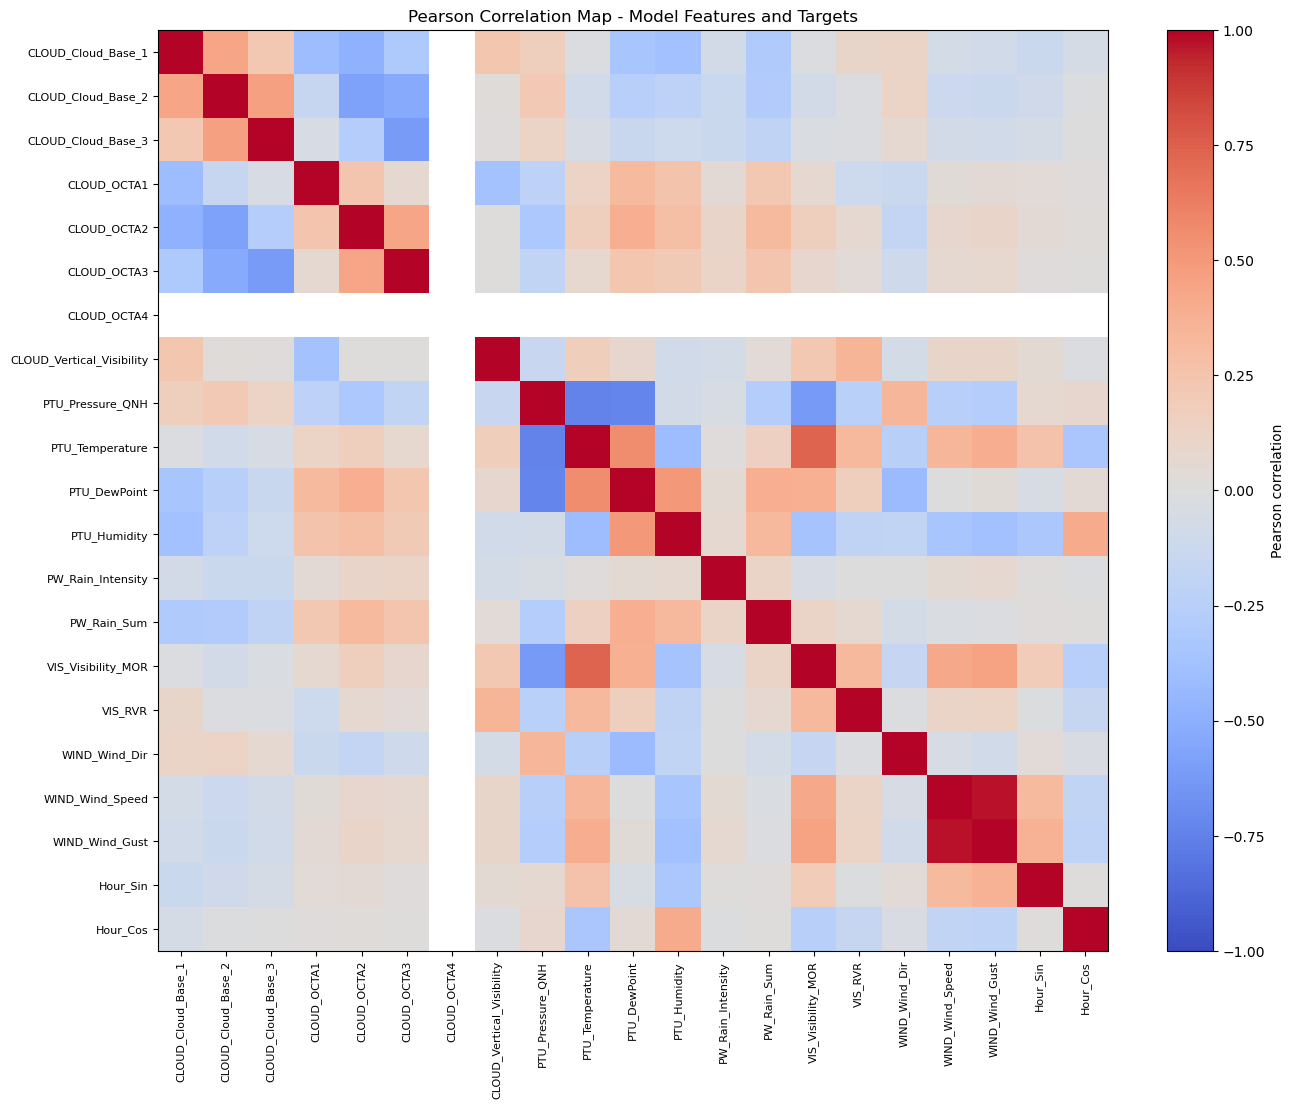

Correlation sample rows: 200000
Rain parameters included: ['PW_Rain_Intensity', 'PW_Rain_Sum']
Rain missingness before model imputation (%):


,rain_parameter,missing_percent
0,PW_Rain_Intensity,0.0
1,PW_Rain_Sum,0.0


Pearson correlations between rain parameters and targets:


,rain_parameter,CLOUD_Vertical_Visibility,VIS_Visibility_MOR
0,PW_Rain_Intensity,-0.068509,-0.047257
1,PW_Rain_Sum,0.037114,0.114126


In [8]:
# Correlation map and rain-feature contribution screening
# This uses the imputed, model-ready training data so correlations match the values
# supplied to the LSTM. Correlation is association, not proof of causal contribution.
CORRELATION_SAMPLE_SIZE = 200_000

# Rebuild the model-ready training frame so this cell can run independently.
correlation_feature_columns = df.select_dtypes(include=[np.number]).columns.tolist()
correlation_train_end = int(len(df) * TRAIN_RATIO)
correlation_frame = df.iloc[:correlation_train_end][correlation_feature_columns].copy()
correlation_frame = correlation_frame.replace([np.inf, -np.inf], np.nan)
usable_correlation_columns = [
    column for column in correlation_feature_columns
    if correlation_frame[column].notna().any()
]
correlation_frame = correlation_frame[usable_correlation_columns]
correlation_frame = correlation_frame.fillna(correlation_frame.median().fillna(0.0))
if len(correlation_frame) > CORRELATION_SAMPLE_SIZE:
    correlation_frame = correlation_frame.sample(
        n=CORRELATION_SAMPLE_SIZE,
        random_state=SEED,
    )

correlation_matrix = correlation_frame.corr(method='pearson')
correlation_matrix.to_csv(ARTIFACT_DIR / 'all_parameters_pearson_correlation.csv')

fig_size = max(12, min(24, 0.65 * len(correlation_matrix.columns)))
fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.82))
image = ax.imshow(
    correlation_matrix.to_numpy(),
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    aspect='auto',
)
ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=90, fontsize=8)
ax.set_yticklabels(correlation_matrix.index, fontsize=8)
ax.set_title('Pearson Correlation Map - Model Features and Targets')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / 'all_parameters_correlation_heatmap.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

rain_columns = [
    column for column in ['PW_Rain_Intensity', 'PW_Rain_Sum']
    if column in correlation_matrix.columns
]
rain_target_correlations = (
    correlation_matrix.loc[rain_columns, TARGET_COLUMNS]
    .rename_axis('rain_parameter')
    .reset_index()
)
rain_target_correlations.to_csv(
    ARTIFACT_DIR / 'rain_target_correlations.csv',
    index=False,
)

raw_rain_missingness = (
    df[rain_columns]
    .isna()
    .mean()
    .mul(100)
    .rename('missing_percent')
    .rename_axis('rain_parameter')
    .reset_index()
)
raw_rain_missingness.to_csv(
    ARTIFACT_DIR / 'rain_missingness_before_model_imputation.csv',
    index=False,
)

print('Correlation sample rows:', len(correlation_frame))
print('Rain parameters included:', rain_columns)
print('Rain missingness before model imputation (%):')
display(raw_rain_missingness)
print('Pearson correlations between rain parameters and targets:')
display(rain_target_correlations)


In [7]:
class LSTMForecaster(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.lstm1 = nn.LSTM(input_size, 128, batch_first=True)
        self.dropout1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(128, 64, batch_first=True)
        self.dropout2 = nn.Dropout(0.2)
        self.dense = nn.Linear(64, 32)
        self.output = nn.Linear(32, output_size)

    def forward(self, inputs):
        outputs, _ = self.lstm1(inputs)
        outputs = self.dropout1(outputs)
        outputs, _ = self.lstm2(outputs)
        outputs = self.dropout2(outputs[:, -1, :])
        outputs = torch.relu(self.dense(outputs))
        return self.output(outputs)

model = LSTMForecaster(len(feature_columns), len(TARGET_COLUMNS)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()
print(model)


LSTMForecaster(
  (lstm1): LSTM(21, 128, batch_first=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (lstm2): LSTM(128, 64, batch_first=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (dense): Linear(in_features=64, out_features=32, bias=True)
  (output): Linear(in_features=32, out_features=2, bias=True)
)


In [8]:
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)), batch_size=BATCH_SIZE, shuffle=False)
validation_loader = DataLoader(TensorDataset(torch.from_numpy(X_validation), torch.from_numpy(y_validation)), batch_size=BATCH_SIZE, shuffle=False)

def run_epoch(loader, training):
    model.train(training)
    total_loss, total_items = 0.0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            predictions = model(inputs)
            loss = criterion(predictions, targets)
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(inputs)
            total_items += len(inputs)
    return total_loss / total_items

history = {'loss': [], 'val_loss': []}
best_validation_loss, best_state, epochs_without_improvement = float('inf'), None, 0
for epoch in range(EPOCHS):
    train_loss = run_epoch(train_loader, True)
    validation_loss = run_epoch(validation_loader, False)
    history['loss'].append(train_loss)
    history['val_loss'].append(validation_loss)
    print(f'Epoch {epoch + 1:03d}/{EPOCHS} - loss: {train_loss:.6f} - val_loss: {validation_loss:.6f}')
    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        epochs_without_improvement = 0
        torch.save(best_state, ARTIFACT_DIR / 'best_lucknow_lstm.pt')
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print('Early stopping.')
            break
model.load_state_dict(best_state)


Epoch 001/50 - loss: 0.059474 - val_loss: 0.017284
Epoch 002/50 - loss: 0.032176 - val_loss: 0.009062
Epoch 003/50 - loss: 0.029655 - val_loss: 0.013637
Epoch 004/50 - loss: 0.027014 - val_loss: 0.009496
Epoch 005/50 - loss: 0.025009 - val_loss: 0.011641
Epoch 006/50 - loss: 0.025186 - val_loss: 0.009665
Epoch 007/50 - loss: 0.022804 - val_loss: 0.008495
Epoch 008/50 - loss: 0.023144 - val_loss: 0.010436
Epoch 009/50 - loss: 0.023778 - val_loss: 0.010911
Epoch 010/50 - loss: 0.021323 - val_loss: 0.011389
Epoch 011/50 - loss: 0.022349 - val_loss: 0.016036
Epoch 012/50 - loss: 0.021571 - val_loss: 0.013903
Epoch 013/50 - loss: 0.022358 - val_loss: 0.015680
Epoch 014/50 - loss: 0.020879 - val_loss: 0.016039
Epoch 015/50 - loss: 0.020279 - val_loss: 0.016484
Early stopping.


<All keys matched successfully>

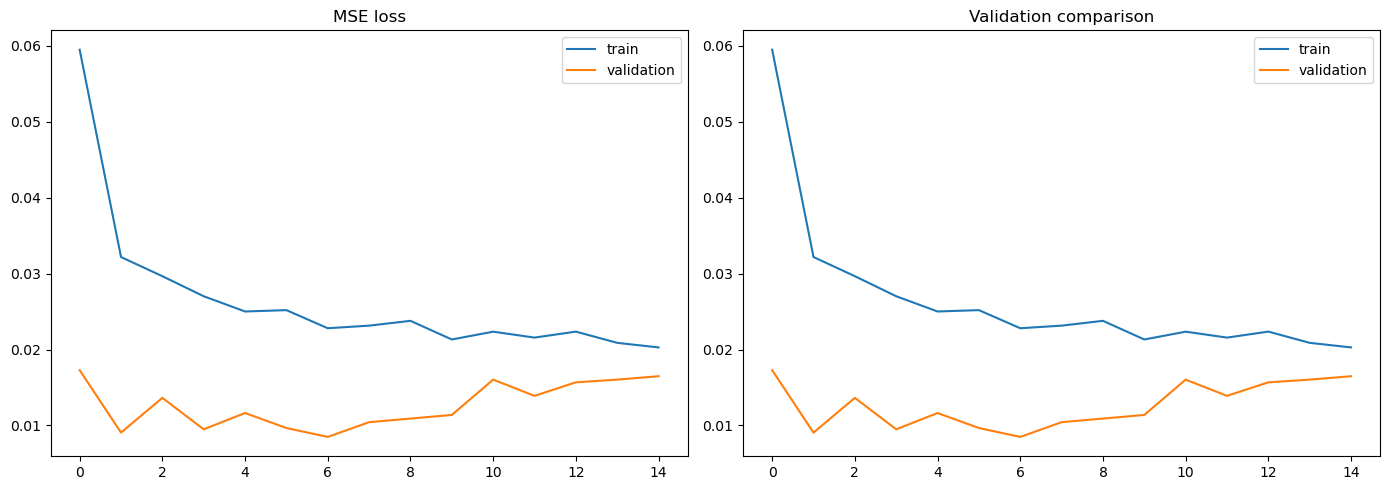

In [9]:
history_frame = pd.DataFrame(history)
history_frame.to_csv(ARTIFACT_DIR / 'training_history.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_frame['loss'], label='train')
axes[0].plot(history_frame['val_loss'], label='validation')
axes[0].set_title('MSE loss')
axes[0].legend()
axes[1].plot(history_frame['loss'], label='train')
axes[1].plot(history_frame['val_loss'], label='validation')
axes[1].set_title('Validation comparison')
axes[1].legend()
plt.tight_layout()
plt.show()


,split,target,MAE,RMSE,R2
0,validation,CLOUD_Vertical_Visibility,15.556597,194.906007,0.924304
1,validation,VIS_Visibility_MOR,168.137360,275.675619,0.991441
2,test,CLOUD_Vertical_Visibility,127.280609,602.309565,0.966201
3,test,VIS_Visibility_MOR,197.312637,298.801029,0.992803


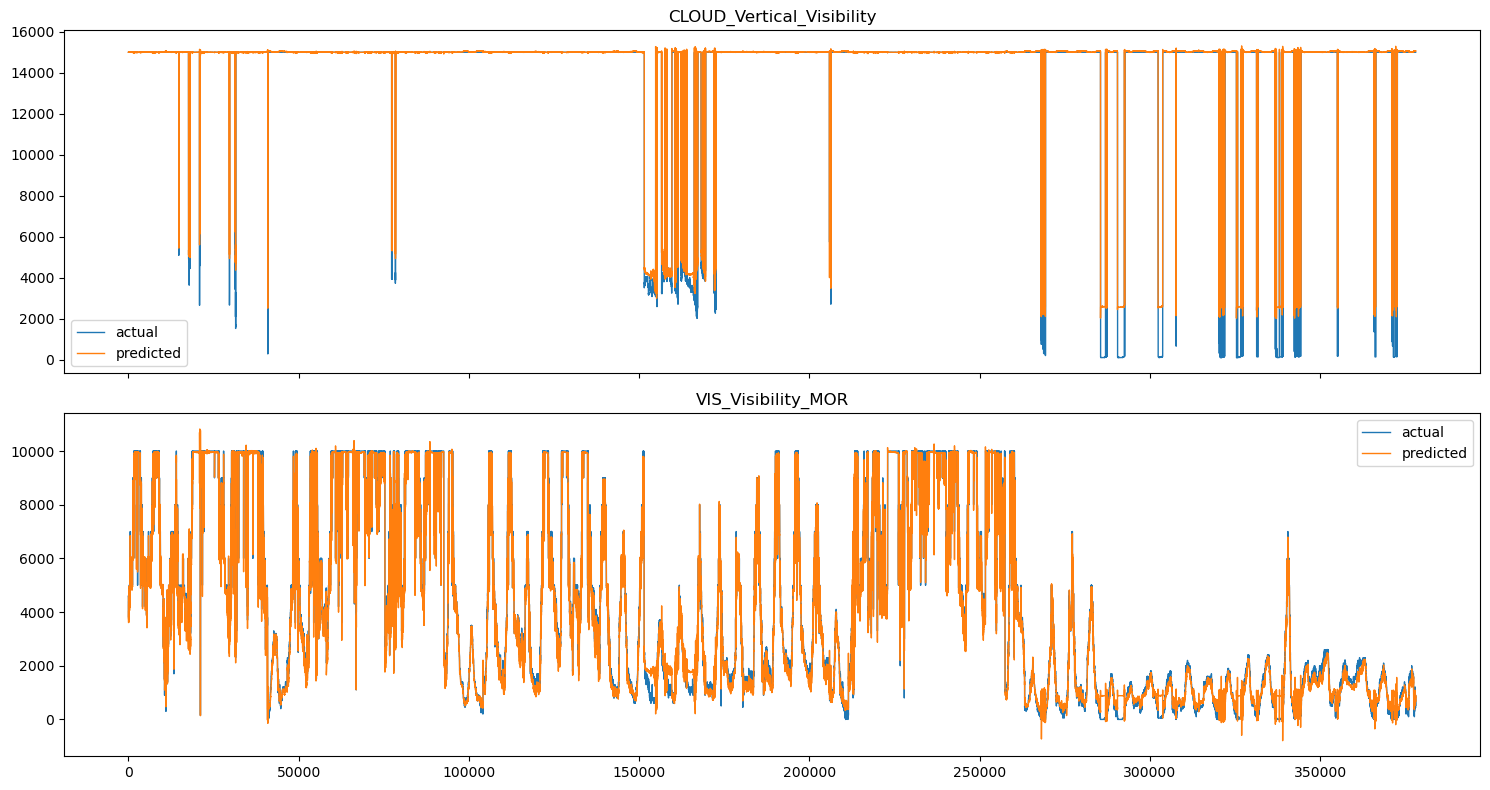

In [ ]:
def predict_numpy(features):
    model.eval()
    loader = DataLoader(torch.from_numpy(features), batch_size=BATCH_SIZE, shuffle=False)
    predictions = []
    with torch.no_grad():
        for inputs in loader:
            predictions.append(model(inputs.to(DEVICE)).cpu().numpy())
    return np.concatenate(predictions, axis=0)

def evaluate_split(name, features, targets):
    predictions_scaled = predict_numpy(features)
    predictions = target_scaler.inverse_transform(predictions_scaled)
    actual = target_scaler.inverse_transform(targets)
    rows = []
    for index, target in enumerate(TARGET_COLUMNS):
        rows.append({
            'split': name,
            'target': target,
            'MAE': mean_absolute_error(actual[:, index], predictions[:, index]),
            'RMSE': mean_squared_error(actual[:, index], predictions[:, index]) ** 0.5,
            'R2': r2_score(actual[:, index], predictions[:, index]),
        })
    return pd.DataFrame(rows), actual, predictions

metrics = pd.concat([
    evaluate_split('validation', X_validation, y_validation)[0],
    evaluate_split('test', X_test, y_test)[0],
], ignore_index=True)
display(metrics)
metrics.to_csv(ARTIFACT_DIR / 'evaluation_metrics.csv', index=False)

test_metrics, actual_test, predictions_test = evaluate_split('test', X_test, y_test)
fig, axes = plt.subplots(len(TARGET_COLUMNS), 1, figsize=(15, 8), sharex=True)
axes = np.atleast_1d(axes)
for index, target in enumerate(TARGET_COLUMNS):
    axes[index].plot(actual_test[:, index], label='actual', linewidth=1)
    axes[index].plot(predictions_test[:, index], label='predicted', linewidth=1)
    axes[index].set_title(target)
    axes[index].legend()
plt.tight_layout()
plt.show()

In [11]:
torch.save(model.state_dict(), ARTIFACT_DIR / 'lucknow_lstm_final.pt')
joblib.dump(feature_scaler, ARTIFACT_DIR / 'feature_scaler.joblib')
joblib.dump(target_scaler, ARTIFACT_DIR / 'target_scaler.joblib')
joblib.dump(
    {
        'feature_columns': feature_columns,
        'target_columns': TARGET_COLUMNS,
        'timestamp_column': TIMESTAMP_COLUMN,
        'lookback': LOOKBACK,
        'horizon': HORIZON,
        'train_ratio': TRAIN_RATIO,
        'validation_ratio': VALIDATION_RATIO,
        'data_file': str(DATA_FILE),
    },
    ARTIFACT_DIR / 'training_config.joblib',
)
print('Saved artifacts to:', ARTIFACT_DIR)


Saved artifacts to: D:\IMD\Lucknow\lucknow_worked\07_LSTM_READY_DATA\lstm_training_artifacts


In [13]:
latest_window = torch.from_numpy(X_test[-1:]).to(DEVICE)
model.eval()
with torch.no_grad():
    next_prediction_scaled = model(latest_window).cpu().numpy()
next_prediction = target_scaler.inverse_transform(next_prediction_scaled)[0]
last_observed_time = test_frame[TIMESTAMP_COLUMN].iloc[-1]
sample_prediction = pd.DataFrame(
    [next_prediction],
    columns=TARGET_COLUMNS,
    index=[last_observed_time + pd.Timedelta(seconds=15 * HORIZON)],
)
sample_prediction.index.name = 'Predicted_Datetime'
display(sample_prediction)


,CLOUD_Vertical_Visibility,VIS_Visibility_MOR
Predicted_Datetime,,
2026-01-01,15063.09082,668.415405


In [15]:
def range_metrics(actual, predicted, target_name):
    ranges = [
        ('low', actual < 1000),
        ('medium', (actual >= 1000) & (actual < 5000)),
        ('high', actual >= 5000),
    ]

    rows = []
    for range_name, mask in ranges:
        if mask.sum() == 0:
            continue
        rows.append({
            'target': target_name,
            'range': range_name,
            'samples': int(mask.sum()),
            'MAE': mean_absolute_error(actual[mask], predicted[mask]),
            'RMSE': mean_squared_error(actual[mask], predicted[mask]) ** 0.5,
            'R2': r2_score(actual[mask], predicted[mask]) if mask.sum() > 1 else np.nan,
        })
    return pd.DataFrame(rows)

range_results = pd.concat(
    [
        range_metrics(actual_test[:, index], predictions_test[:, index], target)
        for index, target in enumerate(TARGET_COLUMNS)
    ],
    ignore_index=True,
)

print('Range-specific test metrics')
display(range_results)
range_results.to_csv(ARTIFACT_DIR / 'range_test_metrics.csv', index=False)

# Correct persistence baseline.
# X_test is feature-scaled, so first undo feature scaling. The resulting
# target values are then already in the original physical units.
last_features_scaled = X_test[:, -1, :]
last_features_original = feature_scaler.inverse_transform(last_features_scaled)
target_feature_indices = [feature_columns.index(target) for target in TARGET_COLUMNS]
baseline_predictions = last_features_original[:, target_feature_indices]

baseline_rows = []
for index, target in enumerate(TARGET_COLUMNS):
    baseline_rows.append({
        'target': target,
        'model_MAE': mean_absolute_error(actual_test[:, index], predictions_test[:, index]),
        'model_RMSE': mean_squared_error(actual_test[:, index], predictions_test[:, index]) ** 0.5,
        'model_R2': r2_score(actual_test[:, index], predictions_test[:, index]),
        'persistence_MAE': mean_absolute_error(actual_test[:, index], baseline_predictions[:, index]),
        'persistence_RMSE': mean_squared_error(actual_test[:, index], baseline_predictions[:, index]) ** 0.5,
        'persistence_R2': r2_score(actual_test[:, index], baseline_predictions[:, index]),
    })

baseline_results = pd.DataFrame(baseline_rows)
baseline_results['MAE_improvement_percent'] = (
    100 * (baseline_results['persistence_MAE'] - baseline_results['model_MAE'])
    / baseline_results['persistence_MAE']
)
baseline_results['RMSE_improvement_percent'] = (
    100 * (baseline_results['persistence_RMSE'] - baseline_results['model_RMSE'])
    / baseline_results['persistence_RMSE']
)

print('LSTM versus corrected persistence baseline')
display(baseline_results)
baseline_results.to_csv(
    ARTIFACT_DIR / 'persistence_baseline_comparison.csv',
    index=False,
)


Range-specific test metrics


,target,range,samples,MAE,RMSE,R2
0,CLOUD_Vertical_Visibility,low,12556,2517.632568,2693.386808,-1133.396973
1,CLOUD_Vertical_Visibility,medium,12176,691.209412,1324.939480,-4.837349
2,CLOUD_Vertical_Visibility,high,353287,22.890518,264.288816,-0.729930
3,VIS_Visibility_MOR,low,79860,276.629456,405.438998,-0.553446
4,VIS_Visibility_MOR,medium,153143,197.133621,243.223936,0.951120
5,VIS_Visibility_MOR,high,145016,153.822098,282.378749,0.979146


LSTM versus corrected persistence baseline


,target,model_MAE,model_RMSE,model_R2,persistence_MAE,persistence_RMSE,persistence_R2,MAE_improvement_percent,RMSE_improvement_percent
0,CLOUD_Vertical_Visibility,127.280609,602.309565,0.966201,12.940503,404.065376,0.984789,-883.583157,-49.062405
1,VIS_Visibility_MOR,197.312637,298.801029,0.992803,35.316612,173.304555,0.997579,-458.696389,-72.413835
